In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
pages = ['A', 'B', 'C', 'D']

links = {
    'A': [],
    'B': ['A', 'C'],
    'C': ['A'],
    'D': ['A', 'B', 'C']
}

print("Web Pages:", pages)
print("Links:", links)

Web Pages: ['A', 'B', 'C', 'D']
Links: {'A': [], 'B': ['A', 'C'], 'C': ['A'], 'D': ['A', 'B', 'C']}


In [3]:
n = len(pages)

matrix = np.zeros((n, n))

for i, page in enumerate(pages):
    for link in links[page]:
        j = pages.index(link)
        matrix[i][j] = 1

print("Adjacency Matrix:")
print(matrix)

Adjacency Matrix:
[[0. 0. 0. 0.]
 [1. 0. 1. 0.]
 [1. 0. 0. 0.]
 [1. 1. 1. 0.]]


In [4]:
d = 0.85
PR = np.ones(n) / n

for iteration in range(100):
    new_PR = np.ones(n) * (1 - d) / n

    for i in range(n):
        if len(links[pages[i]]) > 0:
            for link in links[pages[i]]:
                j = pages.index(link)
                new_PR[j] += d * PR[i] / len(links[pages[i]])
        else:
            new_PR += d * PR[i] / n

    PR = new_PR

print("PageRank Scores:")

for i in range(n):
    print(pages[i], ":", round(PR[i], 4))

PageRank Scores:
A : 0.4514
B : 0.1712
C : 0.244
D : 0.1334


In [5]:
ranked = sorted(zip(pages, PR), key=lambda x: x[1], reverse=True)

print("Pages According to Rank:")

for page, score in ranked:
    print(page, ":", round(score, 4))

Pages According to Rank:
A : 0.4514
C : 0.244
B : 0.1712
D : 0.1334


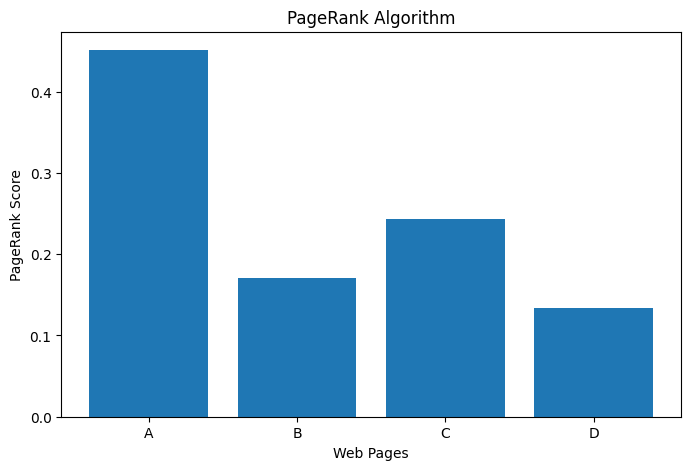

In [6]:
plt.figure(figsize=(8, 5))

plt.bar(pages, PR)

plt.title("PageRank Algorithm")
plt.xlabel("Web Pages")
plt.ylabel("PageRank Score")

plt.show()